# **Deep Learning Project {Tranformers implementation}** - *Reuters Dataset.* - Text Classification
- **Name**            :     Mulagondla Lakshmi Goutham Reddy

- **PRN**          :     230200026

- **Year**         : 3rd Year

- **Course** : Deep Learning

- **Date** : 28 December 2025

In [10]:
import numpy as np
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import ops
from keras import layers

## **Defining Embedding layer**

In [11]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = ops.shape(x)[-1]
        positions = ops.arange(start=0, stop=maxlen, step=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

## **Defining Transformer block**

In [12]:
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = keras.Sequential(
            [layers.Dense(ff_dim, activation="relu"), layers.Dense(embed_dim),]
        )
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output)
        return self.layernorm2(out1 + ffn_output)

### Defining parameters

In [13]:
vocab_size = 10000 # Only consider the top 10k words
maxlen = 200       # Only consider the first 200 words of each movie review
embed_dim = 32
num_heads = 4
ff_dim1 = 32
ff_dim2 = 64
output_dim=46

### **Loading and splitting the Data**

In [14]:
from tensorflow.keras.datasets import reuters

(X_train,y_train),(X_test,y_test) = reuters.load_data(num_words=vocab_size)

Displaying the review and Labels

In [16]:
reverse_word_index = {index + 3: word for word, index in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

def decode_newswire(sequence):
    return " ".join(reverse_word_index.get(i, "?") for i in sequence)


# Print first five decoded newswires with labels
for i in range(5):
    text = decode_newswire(X_train[i])
    label = y_train[i]

    print(f"--- Article {i}  |  (label: {label}) ---\n")
    print(text)
    print("\n")


--- Article 0  |  (label: 3) ---

<START> <UNK> <UNK> said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3


--- Article 1  |  (label: 4) ---

<START> generale de banque sa lt <UNK> br and lt heller overseas corp of chicago have each taken 50 pct stakes in <UNK> company sa <UNK> factors generale de banque said in a statement it gave no financial details of the transaction sa <UNK> <UNK> turnover in 1986 was 17 5 billion belgian francs reuter 3


--- Article 2  |  (label: 3) ---

<START> shr 3 28 dlrs vs 22 cts shr diluted 2 99 dlrs vs 22 cts net 46 0 mln vs 3 328 000 avg shrs 14 0 mln vs 15 2 mln year shr 5 41 dlrs vs 1 56 dlrs shr diluted 4 94 dlrs vs 1 50 dlr

In [17]:
Labels= np.array(reuters.get_label_names())
Labels

array(['cocoa', 'grain', 'veg-oil', 'earn', 'acq', 'wheat', 'copper',
       'housing', 'money-supply', 'coffee', 'sugar', 'trade', 'reserves',
       'ship', 'cotton', 'carcass', 'crude', 'nat-gas', 'cpi', 'money-fx',
       'interest', 'gnp', 'meal-feed', 'alum', 'oilseed', 'gold', 'tin',
       'strategic-metal', 'livestock', 'retail', 'ipi', 'iron-steel',
       'rubber', 'heat', 'jobs', 'lei', 'bop', 'zinc', 'orange',
       'pet-chem', 'dlr', 'gas', 'silver', 'wpi', 'hog', 'lead'],
      dtype='<U15')

### **Padding sequences**

In [18]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train = pad_sequences(X_train, maxlen)
X_test  = pad_sequences(X_test, maxlen)

In [19]:
X_train

array([[  0,   0,   0, ...,  15,  17,  12],
       [  0,   0,   0, ..., 505,  17,  12],
       [  0,   0,   0, ...,  11,  17,  12],
       ...,
       [  0,   0,   0, ..., 407,  17,  12],
       [  0,   0,   0, ..., 364,  17,  12],
       [  0,   0,   0, ..., 113,  17,  12]], dtype=int32)

In [20]:
X_train.shape

(8982, 200)

### **Number of intermediate layers = 1 or num_transformer_layers = 3**

In [21]:
inputs = layers.Input(shape = (maxlen,)) #(batchsize,200,)
embed_layer = TokenAndPositionEmbedding(maxlen = maxlen,vocab_size=vocab_size, embed_dim=embed_dim)
x=embed_layer(inputs) #(batchsize,200,32)
num_transformer_layers = 3
for i in range(num_transformer_layers):
  if i==0 or i==num_transformer_layers-1:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim1)
    x=Transformer_block(x)
  else:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim2)
    x=Transformer_block(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_dim,activation= "softmax")(x)

T_Model_3 = keras.Model(inputs=inputs, outputs=outputs)

In [22]:
T_Model_3.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [23]:
history_3 = T_Model_3.fit(X_train, y_train,
                    batch_size = 32,
                    epochs = 10,
                    validation_data=(X_test, y_test))

Epoch 1/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 33s 54ms/step - accuracy: 0.4595 - loss: 2.1733 - val_accuracy: 0.7400 - val_loss: 1.1453
Epoch 2/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7878 - loss: 0.9201 - val_accuracy: 0.7792 - val_loss: 0.9657
Epoch 3/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8804 - loss: 0.5433 - val_accuracy: 0.7939 - val_loss: 0.9575
Epoch 4/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9278 - loss: 0.3529 - val_accuracy: 0.7890 - val_loss: 1.0208
Epoch 5/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9516 - loss: 0.2286 - val_accuracy: 0.7934 - val_loss: 1.0738
Epoch 6/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9552 - loss: 0.1869 - val_accuracy: 0.7809 - val_loss: 1.1288
Epoch 7/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9592 - loss: 0.1524 - val_accuracy: 0.7711 - val_loss: 1.2224
Epoch 8/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9601 - loss: 0.1361 - val_acc

In [24]:
y_test_3=T_Model_3.predict(X_test)
y_test_3

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step


array([[1.3041456e-04, 9.5366886e-06, 3.5111198e-06, ..., 2.2962035e-06,
        1.8031002e-04, 1.7370068e-08],
       [1.1480626e-03, 5.0304906e-04, 2.4487353e-03, ..., 4.0460332e-06,
        7.0975698e-06, 8.0828841e-06],
       [8.7903973e-06, 9.8508042e-01, 4.5617006e-05, ..., 3.8485137e-05,
        1.0994276e-05, 1.9354742e-08],
       ...,
       [7.3911804e-07, 1.5038917e-04, 1.0576836e-05, ..., 1.6039256e-04,
        5.2090711e-04, 9.0255782e-08],
       [8.4991270e-06, 1.1482811e-01, 3.8747556e-04, ..., 8.2799874e-04,
        9.7383105e-05, 4.8745530e-08],
       [1.2828263e-03, 1.2698794e-02, 3.5852871e-03, ..., 3.4709815e-06,
        2.4266054e-05, 2.1968126e-06]], dtype=float32)

### **Number of intermediate layers = 3 or num_transformer_layers = 5**

In [25]:
inputs = layers.Input(shape = (maxlen,)) #(batchsize,200,)
embed_layer = TokenAndPositionEmbedding(maxlen = maxlen,vocab_size=vocab_size, embed_dim=embed_dim)
x=embed_layer(inputs) #(batchsize,200,32)
num_transformer_layers = 5
for i in range(num_transformer_layers):
  if i==0 or i==num_transformer_layers-1:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim1)
    x=Transformer_block(x)
  else:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim2)
    x=Transformer_block(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_dim,activation= "softmax")(x)

T_Model_5 = keras.Model(inputs=inputs, outputs=outputs)

In [26]:
T_Model_5.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [27]:
history_5 = T_Model_5.fit(X_train, y_train,
                    batch_size = 32,
                    epochs = 10,
                    validation_data=(X_test, y_test))

Epoch 1/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.4724 - loss: 2.1218 - val_accuracy: 0.6843 - val_loss: 1.3445
Epoch 2/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7322 - loss: 1.1174 - val_accuracy: 0.7315 - val_loss: 1.0755
Epoch 3/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8260 - loss: 0.7301 - val_accuracy: 0.7587 - val_loss: 1.0284
Epoch 4/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8749 - loss: 0.5220 - val_accuracy: 0.7373 - val_loss: 1.0939
Epoch 5/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9019 - loss: 0.4162 - val_accuracy: 0.7729 - val_loss: 1.0610
Epoch 6/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9270 - loss: 0.3206 - val_accuracy: 0.7591 - val_loss: 1.0987
Epoch 7/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9370 - loss: 0.2557 - val_accuracy: 0.7711 - val_loss: 1.1749
Epoch 8/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9466 - loss: 0.2071 - val_ac

In [28]:
y_test_5=T_Model_5.predict(X_test)
y_test_5

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step


array([[2.52915750e-04, 3.49526526e-05, 2.88635900e-04, ...,
        4.60294729e-07, 3.85437716e-07, 1.07443730e-05],
       [1.69929548e-03, 1.10026434e-04, 2.96526519e-03, ...,
        6.11878420e-07, 1.58307939e-05, 1.42079580e-06],
       [1.08301139e-03, 9.85256135e-01, 2.47075095e-05, ...,
        6.78253627e-06, 3.07526125e-06, 5.45376097e-05],
       ...,
       [3.87501277e-05, 9.03812543e-05, 2.39250930e-05, ...,
        2.19114924e-07, 4.08449637e-07, 1.96184510e-06],
       [9.47088411e-04, 2.62164301e-03, 8.65646265e-03, ...,
        1.53304645e-05, 1.07452968e-06, 1.82007934e-04],
       [8.04592637e-05, 1.28155365e-03, 5.04986965e-04, ...,
        1.60598356e-04, 1.22792379e-04, 9.30637470e-05]], dtype=float32)

### **Number of intermediate layers = 5 or num_transformer_layers = 7**

In [29]:
inputs = layers.Input(shape = (maxlen,)) #(batchsize,200,)
embed_layer = TokenAndPositionEmbedding(maxlen = maxlen,vocab_size=vocab_size, embed_dim=embed_dim)
x=embed_layer(inputs) #(batchsize,200,32)
num_transformer_layers = 7
for i in range(num_transformer_layers):
  if i==0 or i==num_transformer_layers-1:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim1)
    x=Transformer_block(x)
  else:
    Transformer_block = TransformerBlock(embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim2)
    x=Transformer_block(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_dim,activation= "softmax")(x)

T_Model_7 = keras.Model(inputs=inputs, outputs=outputs)

In [30]:
T_Model_7.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [31]:
history_7 = T_Model_7.fit(X_train, y_train,
                    batch_size = 32,
                    epochs = 10,
                    validation_data=(X_test, y_test))

Epoch 1/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 64s 113ms/step - accuracy: 0.4574 - loss: 2.2170 - val_accuracy: 0.6389 - val_loss: 1.5212
Epoch 2/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 43s 30ms/step - accuracy: 0.7098 - loss: 1.2354 - val_accuracy: 0.6701 - val_loss: 1.2988
Epoch 3/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.7687 - loss: 0.9264 - val_accuracy: 0.7248 - val_loss: 1.1112
Epoch 4/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.8166 - loss: 0.7462 - val_accuracy: 0.7395 - val_loss: 1.0980
Epoch 5/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.8534 - loss: 0.5995 - val_accuracy: 0.7493 - val_loss: 1.1036
Epoch 6/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.8804 - loss: 0.5000 - val_accuracy: 0.7404 - val_loss: 1.1972
Epoch 7/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.8957 - loss: 0.4327 - val_accuracy: 0.7547 - val_loss: 1.1436
Epoch 8/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9162 - loss: 0.3626 - val_

In [32]:
y_test_7=T_Model_7.predict(X_test)
y_test_7

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step


array([[7.0807786e-05, 2.1995969e-02, 9.7804143e-05, ..., 1.8797335e-05,
        8.4707756e-07, 1.6614039e-06],
       [7.3038372e-03, 3.0307721e-03, 2.7333587e-04, ..., 5.9530590e-05,
        6.8391993e-05, 8.8795759e-06],
       [2.7161126e-05, 9.7609520e-01, 1.8475149e-04, ..., 9.9093177e-06,
        3.2320499e-05, 7.2064497e-05],
       ...,
       [5.8550475e-05, 5.9091100e-03, 1.8728122e-05, ..., 1.2353896e-05,
        1.1807335e-06, 6.3328421e-06],
       [5.4774679e-05, 2.3872532e-02, 7.4816220e-05, ..., 2.5861935e-05,
        1.5247406e-06, 6.8051431e-06],
       [1.0802675e-02, 3.9131060e-01, 2.7591219e-02, ..., 9.6252013e-05,
        3.9031191e-05, 1.2259142e-04]], dtype=float32)

### **Computing Confusion matrix**


Generating Confusion Matrix for Transformer_3...



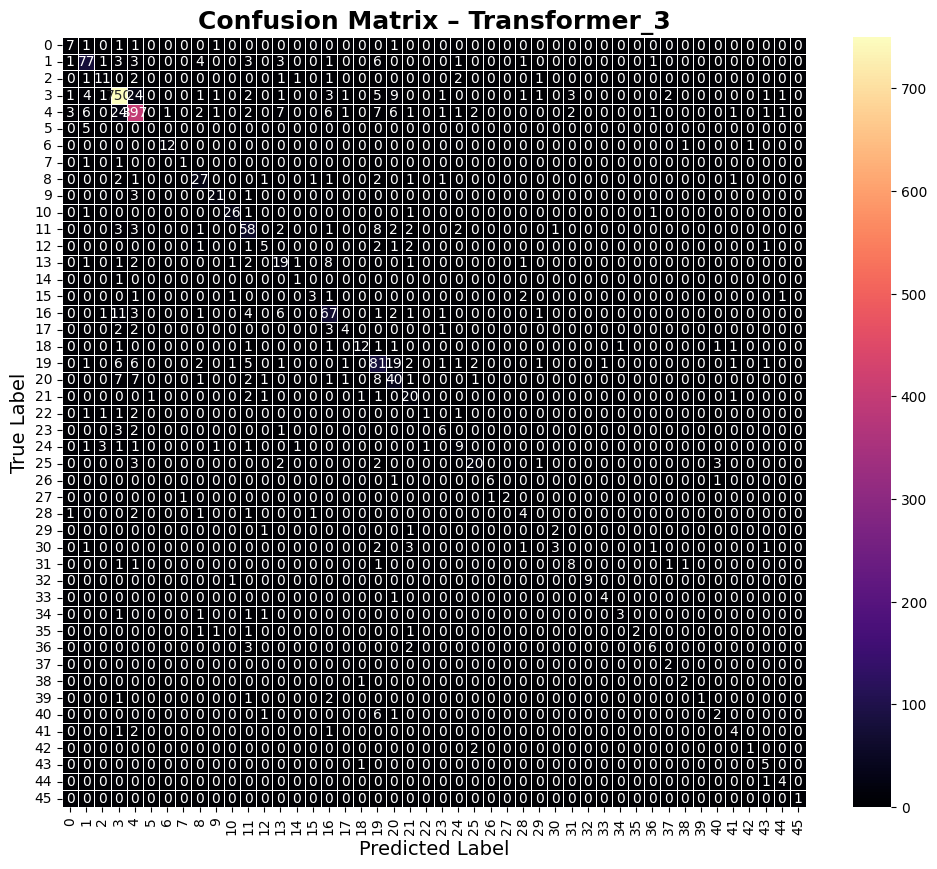


Generating Confusion Matrix for Transformer_5...



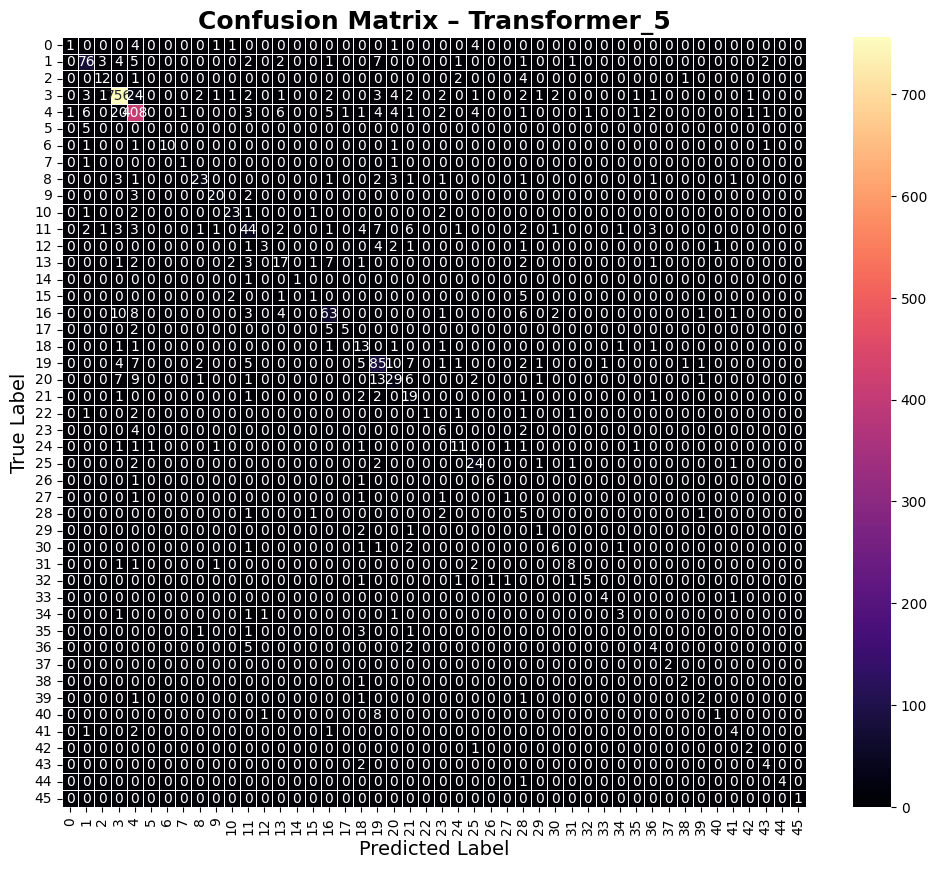


Generating Confusion Matrix for Transformer_7...



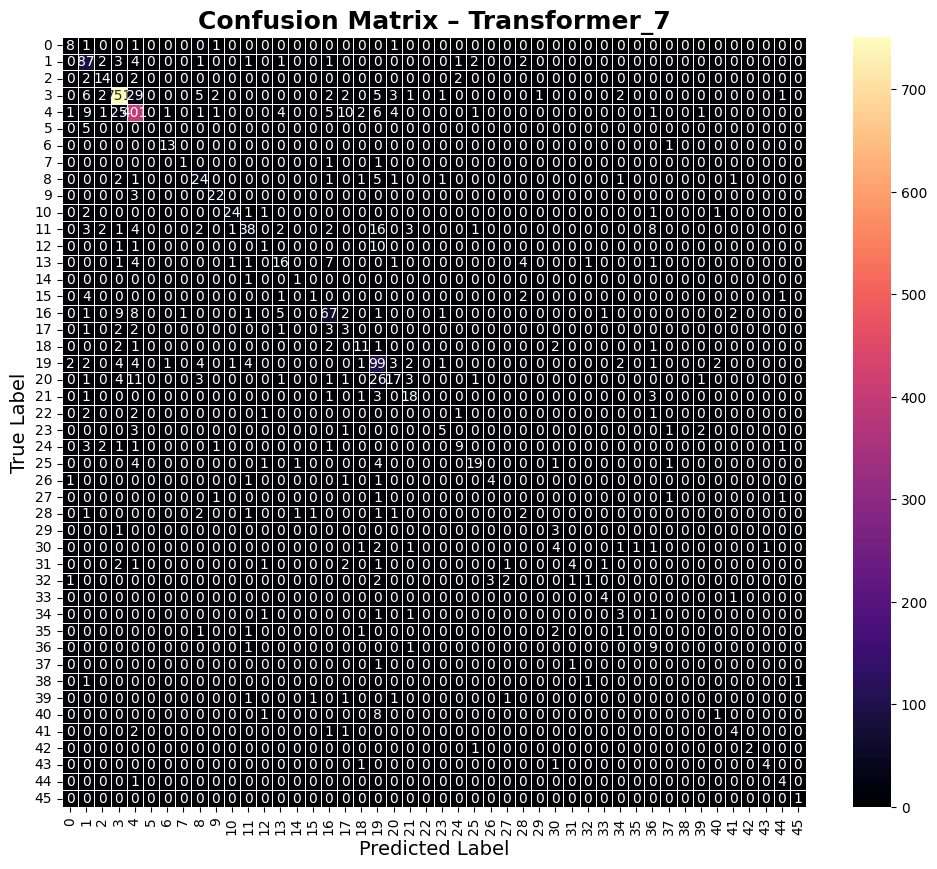

In [33]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

models = {
    "Transformer_3": T_Model_3,
    "Transformer_5": T_Model_5,
    "Transformer_7": T_Model_7,
}

for name, model in models.items():
    print(f"\nGenerating Confusion Matrix for {name}...\n")

    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm,
        cmap="magma",
        annot=True,
        fmt="d",
        linewidths=0.5,
        cbar=True
    )

    plt.title(f"Confusion Matrix – {name}", fontsize=18, fontweight="bold")
    plt.xlabel("Predicted Label", fontsize=14)
    plt.ylabel("True Label", fontsize=14)

    plt.show()


### **Computing F1-scores**

In [43]:
from sklearn.metrics import f1_score

models = {
    "Transformer_3": T_Model_3,
    "Transformer_5": T_Model_5,
    "Transformer_7": T_Model_7,
}

f1_scores = {}

for name, model in models.items():

    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)


    f1 = f1_score(y_test, y_pred, average='macro')
    f1_scores[name] = f1

    print(f"{name} F1-score: {f1:.4f}")


Transformer_3 F1-score: 0.5661
Transformer_5 F1-score: 0.5366
Transformer_7 F1-score: 0.4429


In [44]:
test_loss_3, test_acc_3 = T_Model_3.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_acc_3)


Test Accuracy: 0.7764915227890015


In [45]:
test_loss_5, test_acc_5 = T_Model_5.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_acc_5)


Test Accuracy: 0.7644701600074768


In [46]:
test_loss_7, test_acc_7 = T_Model_7.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_acc_7)


Test Accuracy: 0.7555654644966125


### **Plotting the F1-scores**
F-1 scores all the below models are plotted:
- Transformer { 3 encoder blocks }
- Transformer { 5 encoder blocks }
- Transformer { 7 encoder blocks }
- SimpleRNN
- LSTM
- GRU
- BiSimpleRNN
- BiLSTM
- BiGRU

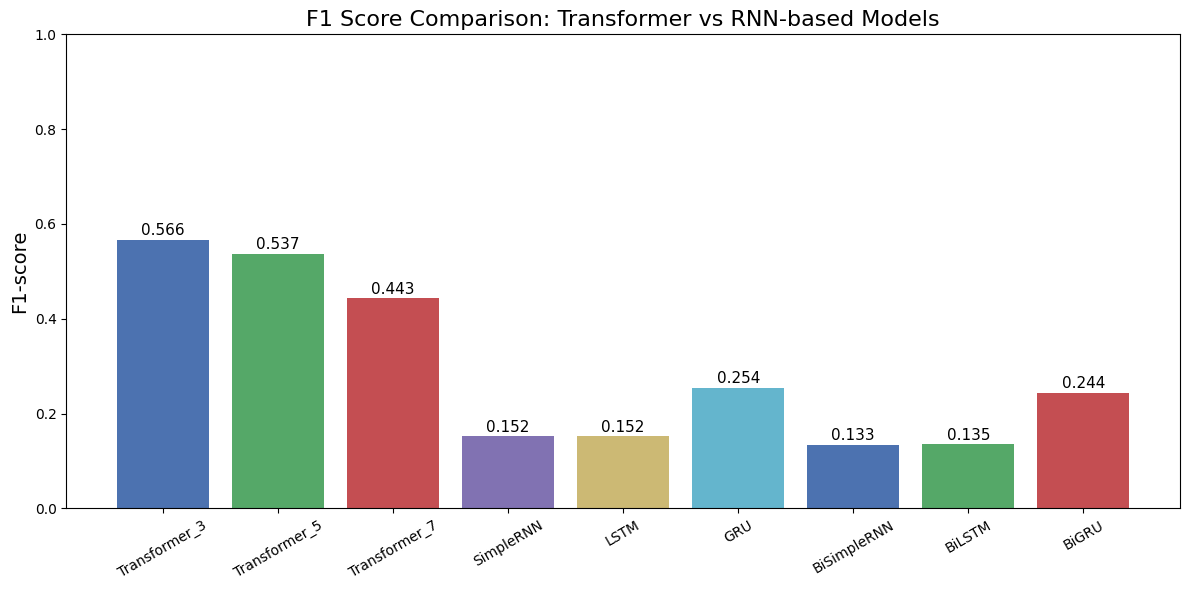

In [48]:
names_t = list(f1_scores.keys())
scores_t = list(f1_scores.values())

models_rnn = [
    "SimpleRNN",
    "LSTM",
    "GRU",
    "BiSimpleRNN",
    "BiLSTM",
    "BiGRU"
]

scores_rnn = [
    0.1520,
    0.1522,
    0.2535,
    0.1333,
    0.1349,
    0.2437
]

all_models = names_t + models_rnn
all_scores = scores_t + scores_rnn

colors = [
    '#4c72b0', '#55a868', '#c44e52',
    '#8172b2', '#ccb974', '#64b5cd',
    '#4c72b0', '#55a868', '#c44e52'
]

plt.figure(figsize=(12, 6))
bars = plt.bar(all_models, all_scores, color=colors)

plt.title("F1 Score Comparison: Transformer vs RNN-based Models", fontsize=16)
plt.ylabel("F1-score", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=30)

for bar, score in zip(bars, all_scores):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{score:.3f}",
        ha='center',
        fontsize=11
    )

plt.tight_layout()
plt.show()


### **Observations:**
From the above we can see the tranformer model models perform much better than the RNN, LSTM, GRU and the bidirectional models. This can be understood by the introduction of attention layers in transformers which does a better representation of words and learning of relations using attention mechanisms.
Within the tranformer models we can see that the model with less number of encoder blocks are having the highest F1-score i.e., Tranformer with 3 encoder blocks.

Transformer_3>Transformer_5>Transformer_7.

There is also a difference between the Training and Testing accuracy in Transformer models. This seems that these models are extensively learning the training data leading to overfitting because of the less amount of data.
An observation is there is lack of data and when we are increasing model complexity with more and more encoder blocks then the models it tending to perform poorer than the model with less number of encoder blocks.

### **Resources used:**
The following resources were used
1. Text classification implementation usign Transformers.   
https://keras.io/examples/nlp/text_classification_with_transformer/

2. Tensorflow encoder block implementation.
https://www.tensorflow.org/text/tutorials/transformer#the_encoder_layer

3. Also used ChatGPT to understand more about keras, ops, layers, and the packages that were are importing.
